In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from itertools import combinations

from google.colab import files

In [2]:
uploaded = files.upload()

file_name = next(
    name for name in uploaded
    if name.lower().endswith(".csv")
)

df = pd.read_csv(file_name)

print("Dataset shape:", df.shape)
display(df.head())
print(df.columns.tolist())

Saving Atlantic_United_Kingdom.csv to Atlantic_United_Kingdom.csv
Dataset shape: (27800, 10)


,date,position,song,artist,popularity,duration_ms,album_type,total_tracks,is_explicit,album_cover_url
0,18-05-2024,1,Tattoo,Loreen,89,183374,single,1,False,https://i.scdn.co/image/ab67616d0000b2732b0ba8...
1,18-05-2024,2,Daylight,David Kushner,96,212953,single,1,False,https://i.scdn.co/image/ab67616d0000b27395ca6a...
2,18-05-2024,3,Cha Cha Cha,Käärijä,86,175161,single,1,False,https://i.scdn.co/image/ab67616d0000b273e9973a...
3,18-05-2024,4,Miracle (with Ellie Goulding),Calvin Harris & Ellie Goulding,91,186496,single,1,False,https://i.scdn.co/image/ab67616d0000b273c58e22...
4,18-05-2024,5,Queen of Kings,Alessandra,85,147979,single,1,False,https://i.scdn.co/image/ab67616d0000b2732c9eea...


['date', 'position', 'song', 'artist', 'popularity', 'duration_ms', 'album_type', 'total_tracks', 'is_explicit', 'album_cover_url']


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
import plotly.express as px
from itertools import combinations
from collections import Counter
from IPython.display import display

# Existing cleaned DataFrame: df
df.columns = df.columns.str.strip().str.lower()

# Required columns check
required_cols = [
    "artist", "position", "song", "duration_ms",
    "album_type", "is_explicit"
]

missing_cols = [col for col in required_cols if col not in df.columns]

if missing_cols:
    print("Missing columns:", missing_cols)
    print("Available columns:", df.columns.tolist())
else:
    print("All required columns are available!")

# Clean data types
df["artist"] = df["artist"].fillna("Unknown Artist").astype(str).str.strip()
df["position"] = pd.to_numeric(df["position"], errors="coerce")
df["duration_ms"] = pd.to_numeric(df["duration_ms"], errors="coerce")
df["duration_min"] = df["duration_ms"] / 60000

# Explicit values ko Boolean mein convert karo
df["is_explicit"] = (
    df["is_explicit"].astype(str).str.lower()
    .isin(["true", "1", "yes", "y", "explicit"])
)

# Artist collaborations ko split karo
df["artist_list"] = df["artist"].apply(
    lambda x: [a.strip() for a in x.split("&") if a.strip()]
)

df["is_collab"] = df["artist_list"].apply(lambda x: len(x) > 1)
df["collaborator_count"] = df["artist_list"].apply(len)

df["rank_group"] = np.where(
    df["position"] <= 10,
    "Top 10",
    "Positions 11–50"
)

print("Dataset shape:", df.shape)
display(df.head())

All required columns are available!
Dataset shape: (27800, 15)


,date,position,song,artist,popularity,duration_ms,album_type,total_tracks,is_explicit,album_cover_url,duration_min,artist_list,is_collab,collaborator_count,rank_group
0,18-05-2024,1,Tattoo,Loreen,89,183374,single,1,False,https://i.scdn.co/image/ab67616d0000b2732b0ba8...,3.056233,[Loreen],False,1,Top 10
1,18-05-2024,2,Daylight,David Kushner,96,212953,single,1,False,https://i.scdn.co/image/ab67616d0000b27395ca6a...,3.549217,[David Kushner],False,1,Top 10
2,18-05-2024,3,Cha Cha Cha,Käärijä,86,175161,single,1,False,https://i.scdn.co/image/ab67616d0000b273e9973a...,2.919350,[Käärijä],False,1,Top 10
3,18-05-2024,4,Miracle (with Ellie Goulding),Calvin Harris & Ellie Goulding,91,186496,single,1,False,https://i.scdn.co/image/ab67616d0000b273c58e22...,3.108267,"[Calvin Harris, Ellie Goulding]",True,2,Top 10
4,18-05-2024,5,Queen of Kings,Alessandra,85,147979,single,1,False,https://i.scdn.co/image/ab67616d0000b2732c9eea...,2.466317,[Alessandra],False,1,Top 10


In [4]:
# Data cleaning and feature engineering
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import networkx as nx
from IPython.display import display, Markdown

# Standardize column names
df.columns = df.columns.str.strip().str.lower()

# Check required columns
required = ["date", "position", "song", "artist",
            "duration_ms", "album_type"]

missing = [col for col in required if col not in df.columns]
if missing:
    raise ValueError(
        f"Missing columns: {missing}\nAvailable columns: {df.columns.tolist()}"
    )

# Handle explicit column naming
if "is_explicit" not in df.columns:
    if "explicit" in df.columns:
        df.rename(columns={"explicit": "is_explicit"}, inplace=True)
    else:
        df["is_explicit"] = False

# Convert data types
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["position"] = pd.to_numeric(df["position"], errors="coerce")
df["duration_ms"] = pd.to_numeric(df["duration_ms"], errors="coerce")

# Clean text columns
for col in ["song", "artist", "album_type"]:
    df[col] = df[col].astype("string").str.strip()

df = df.dropna(subset=["date", "song", "artist", "position"]).copy()
df = df.drop_duplicates(subset=["date", "position", "song", "artist"])

# Convert duration to minutes
df["duration_min"] = df["duration_ms"] / 60000

# Normalize explicit values
df["is_explicit"] = (
    df["is_explicit"]
    .astype(str).str.lower()
    .isin(["true", "1", "yes", "y", "explicit"])
)

# Identify collaborations using &
df["artist_list"] = df["artist"].apply(
    lambda x: [a.strip() for a in str(x).split("&") if a.strip()]
)
df["is_collab"] = df["artist_list"].apply(lambda x: len(x) > 1)
df["collaborator_count"] = df["artist_list"].apply(len)

# Normalize album type
df["album_type"] = df["album_type"].str.title()

# Rank group
df["rank_group"] = np.where(df["position"] <= 10, "Top 10", "Positions 11–50")

# Popularity may not exist in every dataset
if "popularity" in df.columns:
    df["popularity"] = pd.to_numeric(df["popularity"], errors="coerce")

print("Cleaning complete!")
print("Rows:", len(df))
print("Date range:", df["date"].min(), "to", df["date"].max())
display(df.head())


/tmp/ipykernel_1183/358488514.py:30: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df["date"] = pd.to_datetime(df["date"], errors="coerce")


Cleaning complete!
Rows: 27785
Date range: 2024-05-18 00:00:00 to 2025-11-27 00:00:00


,date,position,song,artist,popularity,duration_ms,album_type,total_tracks,is_explicit,album_cover_url,duration_min,artist_list,is_collab,collaborator_count,rank_group
0,2024-05-18,1,Tattoo,Loreen,89,183374,Single,1,False,https://i.scdn.co/image/ab67616d0000b2732b0ba8...,3.056233,[Loreen],False,1,Top 10
1,2024-05-18,2,Daylight,David Kushner,96,212953,Single,1,False,https://i.scdn.co/image/ab67616d0000b27395ca6a...,3.549217,[David Kushner],False,1,Top 10
2,2024-05-18,3,Cha Cha Cha,Käärijä,86,175161,Single,1,False,https://i.scdn.co/image/ab67616d0000b273e9973a...,2.919350,[Käärijä],False,1,Top 10
3,2024-05-18,4,Miracle (with Ellie Goulding),Calvin Harris & Ellie Goulding,91,186496,Single,1,False,https://i.scdn.co/image/ab67616d0000b273c58e22...,3.108267,"[Calvin Harris, Ellie Goulding]",True,2,Top 10
4,2024-05-18,5,Queen of Kings,Alessandra,85,147979,Single,1,False,https://i.scdn.co/image/ab67616d0000b2732c9eea...,2.466317,[Alessandra],False,1,Top 10


In [5]:
# Convert 'date' column to datetime type first
df["date"] = pd.to_datetime(df["date"], format="%d-%m-%Y", errors="coerce")

daily_counts = (
    df.groupby(df["date"].dt.date)
    .size()
    .reset_index(name="track_count")
)

print("Dates with other than 50 records:")
display(daily_counts[daily_counts["track_count"] != 50])

print("Start date:", df["date"].min())
print("End date:", df["date"].max())
print("Unique dates:", df["date"].nunique())

Dates with other than 50 records:


,date,track_count
287,2025-03-01,85


Start date: 2024-05-18 00:00:00
End date: 2025-11-27 00:00:00
Unique dates: 555


In [8]:
from collections import Counter

# Calculate artist_counts first to fix the NameError
all_artists = [artist for artists in df["artist_list"] for artist in artists]
artist_counts = Counter(all_artists)

leaderboard = pd.DataFrame(
    artist_counts.most_common(15),
    columns=["Artist", "Appearances"]
)

display(leaderboard)

fig = px.bar(
    leaderboard.sort_values("Appearances"),
    x="Appearances",
    y="Artist",
    orientation="h",
    title="Top 15 Artists by Playlist Appearances",
    text="Appearances"
)

fig.update_layout(
    xaxis_title="Artist appearances",
    yaxis_title="Artist",
    height=600
)

fig.show()

,Artist,Appearances
0,Taylor Swift,2092
1,Sabrina Carpenter,965
2,Billie Eilish,888
3,Olivia Rodrigo,694
4,Chappell Roan,634
5,Benson Boone,537
6,Central Cee,534
7,Drake,518
8,The Killers,512
9,Dua Lipa,485


In [10]:

#Top 10 artist leaderboard
artist_counts = df.explode("artist_list")["artist_list"].value_counts()
top10_artists = artist_counts.head(10).sort_values()

fig = px.bar(
    x=top10_artists.values,
    y=top10_artists.index,
    orientation="h",
    labels={"x": "Track appearances", "y": "Artist"},
    title="Top 10 Artists by Track Appearances"
)
fig.show()


In [13]:
# Exploding the artist list from our main DataFrame 'df' to create individual artist records
artist_data = df.explode("artist_list")

unique_artists = artist_data["artist_list"].nunique()

diversity_score = unique_artists / len(df)

all_artist_counts = artist_data["artist_list"].value_counts()

top5_share = (
    all_artist_counts.head(5).sum() / len(df)
) * 100

print("Unique artists:", unique_artists)
print("Diversity score:", round(diversity_score, 4))
print("Top 5 artist appearance share:", round(top5_share, 2), "%")

Unique artists: 363
Diversity score: 0.0131
Top 5 artist appearance share: 18.98 %


track_type
Solo artist      22663
Collaboration     5122
Name: count, dtype: int64


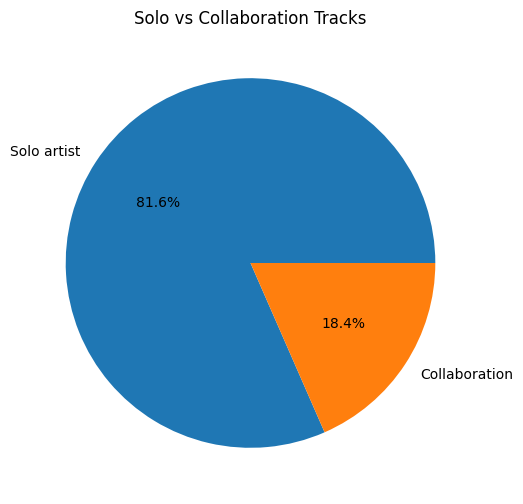

Collaboration ratio: 18.43 %


In [14]:
df["artist_count"] = df["artist_list"].apply(
    lambda artists: len([
        a for a in artists if a.strip()
    ])
)

df["track_type"] = np.where(
    df["artist_count"] > 1,
    "Collaboration",
    "Solo artist"
)

print(df["track_type"].value_counts())

df["track_type"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%",
    figsize=(6, 6)
)

plt.title("Solo vs Collaboration Tracks")
plt.ylabel("")
plt.show()

print(
    "Collaboration ratio:",
    round((df["track_type"] == "Collaboration").mean() * 100, 2),
    "%"
)

In [15]:
explicit_analysis = (
    df.groupby("rank_group", observed=False)["is_explicit"]
    .agg(["sum", "count", "mean"])
    .reset_index()
)

explicit_analysis["Explicit Share (%)"] = (
    explicit_analysis["mean"] * 100
)

display(explicit_analysis)

fig = px.bar(
    explicit_analysis,
    x="rank_group",
    y="Explicit Share (%)",
    text="Explicit Share (%)",
    title="Explicit Content Share by Rank Group"
)

fig.update_traces(texttemplate="%{text:.1f}%", textposition="outside")
fig.show()

# Overall explicit vs clean
explicit_counts = (
    df["is_explicit"]
    .map({True: "Explicit", False: "Clean"})
    .value_counts()
    .rename_axis("Content Type")
    .reset_index(name="Track Count")
)

fig = px.pie(
    explicit_counts,
    names="Content Type",
    values="Track Count",
    hole=0.4,
    title="Explicit vs Clean Track Distribution"
)

fig.show()

,rank_group,sum,count,mean,Explicit Share (%)
0,Positions 11–50,6664,22233,0.299735,29.973463
1,Top 10,2242,5552,0.403818,40.381844


In [16]:

# Collaboration rate — Top 10 vs remaining positions
collab_summary = (
    df.groupby("rank_group")["is_collab"]
      .mean().mul(100).reset_index()
)
collab_summary.columns = ["Rank Group", "Collaboration Rate (%)"]

fig = px.bar(
    collab_summary,
    x="Rank Group",
    y="Collaboration Rate (%)",
    text_auto=".2f",
    title="Collaboration Rate: Top 10 vs Positions 11–50"
)
fig.show()


,count
is_explicit,
Non-explicit,18879
Explicit,8906


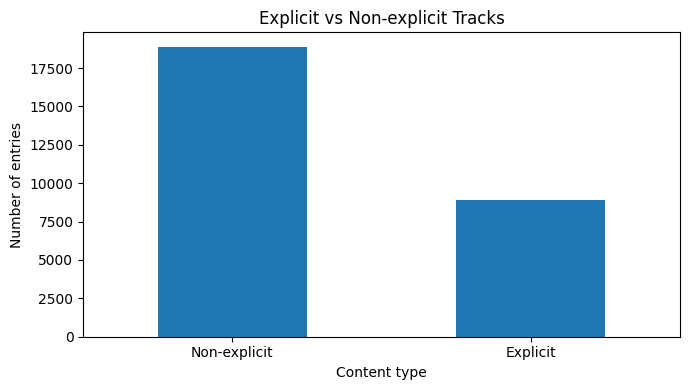

In [17]:
explicit_counts = (
    df["is_explicit"]
    .map({True: "Explicit", False: "Non-explicit"})
    .fillna("Unknown")
    .value_counts()
)

display(explicit_counts)

explicit_counts.plot(
    kind="bar",
    figsize=(7, 4)
)

plt.title("Explicit vs Non-explicit Tracks")
plt.xlabel("Content type")
plt.ylabel("Number of entries")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

,count
album_type,
Album,16661
Single,11046
Compilation,78


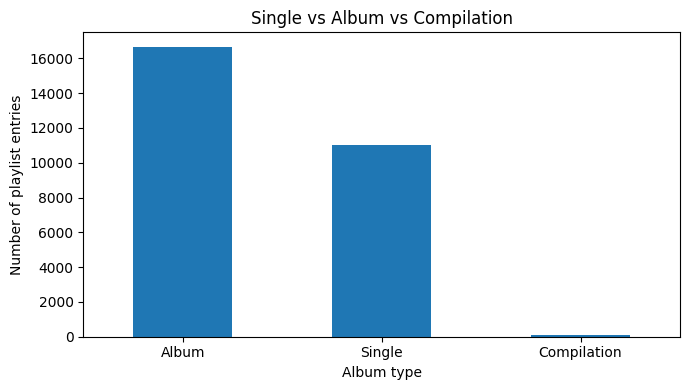

In [18]:
album_counts = df["album_type"].value_counts()

display(album_counts)

album_counts.plot(
    kind="bar",
    figsize=(7, 4)
)

plt.title("Single vs Album vs Compilation")
plt.xlabel("Album type")
plt.ylabel("Number of playlist entries")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

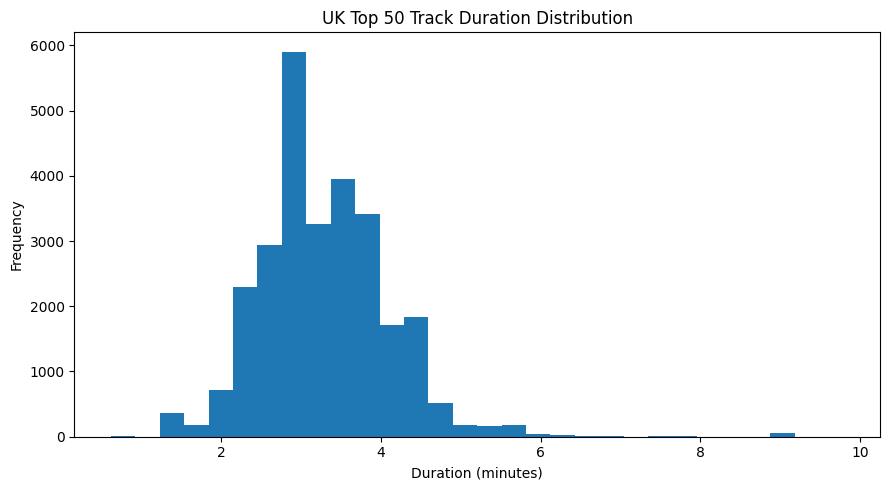

Average duration: 3.29 minutes
Median duration: 3.11 minutes


In [19]:
# Calculate duration in minutes from duration_ms
df["duration_min"] = df["duration_ms"] / 60000

plt.figure(figsize=(9, 5))
plt.hist(
    df["duration_min"].dropna(),
    bins=30
)

plt.title("UK Top 50 Track Duration Distribution")
plt.xlabel("Duration (minutes)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

print("Average duration:", round(df["duration_min"].mean(), 2), "minutes")
print("Median duration:", round(df["duration_min"].median(), 2), "minutes")

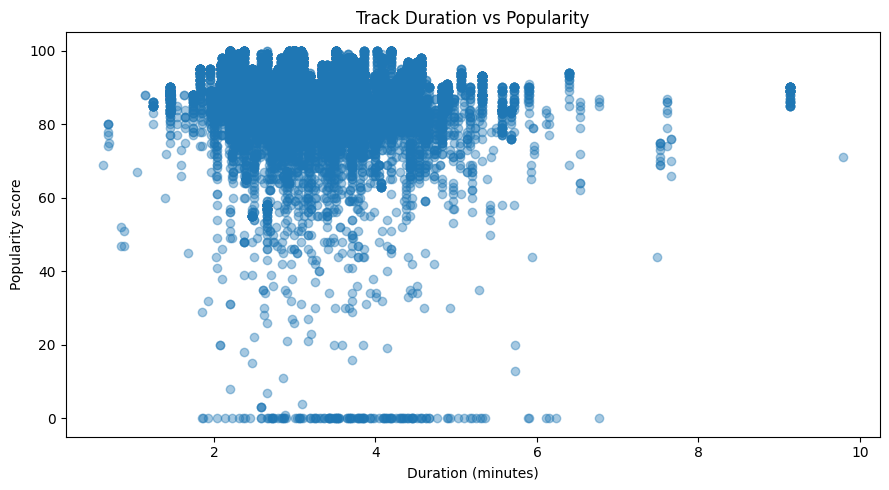

Correlation: -0.07287836349458769


In [20]:
plt.figure(figsize=(9, 5))

plt.scatter(
    df["duration_min"],
    df["popularity"],
    alpha=0.4
)

plt.title("Track Duration vs Popularity")
plt.xlabel("Duration (minutes)")
plt.ylabel("Popularity score")
plt.tight_layout()
plt.show()

print(
    "Correlation:",
    df[["duration_min", "popularity"]].corr().iloc[0, 1]
)

Number of artist nodes: 165
Number of collaboration connections: 154


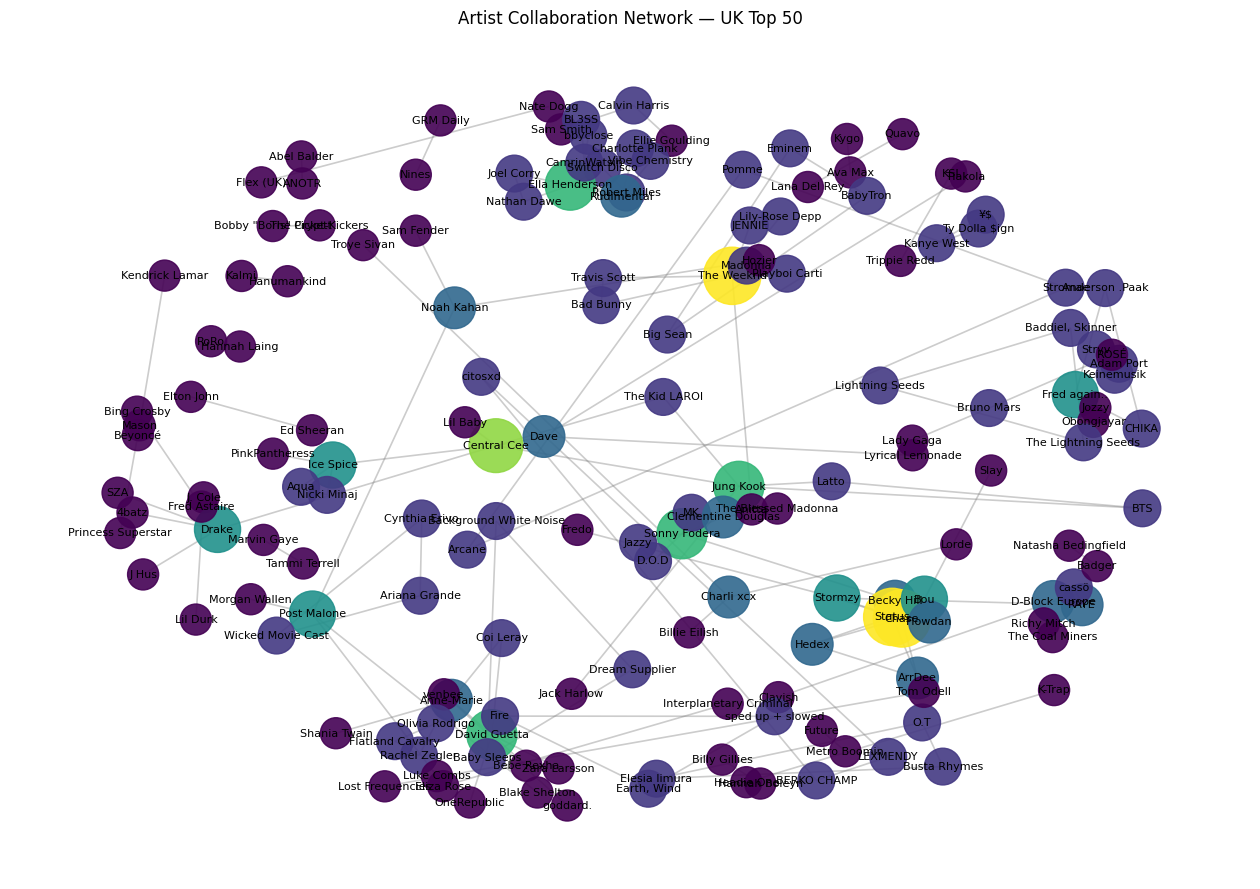

,Artist,Collaboration Partners
0,The Weeknd,7
1,Chase,7
2,Status,7
3,Central Cee,6
4,Ella Henderson,5
5,David Guetta,5
6,Jung Kook,5
7,Sonny Fodera,5
8,Ice Spice,4
9,Drake,4


In [21]:
G = nx.Graph()

for _, row in df.iterrows():
    artists = list(dict.fromkeys(row["artist_list"]))

    # Sirf collaborative tracks se network banao
    if len(artists) > 1:
        G.add_nodes_from(artists)

        for artist_a, artist_b in combinations(artists, 2):
            if G.has_edge(artist_a, artist_b):
                G[artist_a][artist_b]["weight"] += 1
            else:
                G.add_edge(artist_a, artist_b, weight=1)

print("Number of artist nodes:", G.number_of_nodes())
print("Number of collaboration connections:", G.number_of_edges())

if G.number_of_edges() > 0:
    plt.figure(figsize=(16, 11))

    pos = nx.spring_layout(G, seed=42, k=0.8)

    degrees = dict(G.degree())
    node_sizes = [
        300 + degrees[node] * 200
        for node in G.nodes()
    ]

    nx.draw_networkx_edges(
        G, pos,
        alpha=0.4,
        width=1.2,
        edge_color="gray"
    )

    nx.draw_networkx_nodes(
        G, pos,
        node_size=node_sizes,
        node_color=list(degrees.values()),
        cmap=plt.cm.viridis,
        alpha=0.9
    )

    nx.draw_networkx_labels(
        G, pos,
        font_size=8
    )

    plt.title("Artist Collaboration Network — UK Top 50")
    plt.axis("off")
    plt.show()

    # Most connected artists
    network_leaderboard = pd.DataFrame(
        sorted(degrees.items(), key=lambda x: x[1], reverse=True),
        columns=["Artist", "Collaboration Partners"]
    )

    display(network_leaderboard.head(15))

else:
    print("No collaborations found. Check artist names and the '&' delimiter.")

,track_type
rank_group,
Positions 11–50,18.432060
Top 10,18.443804


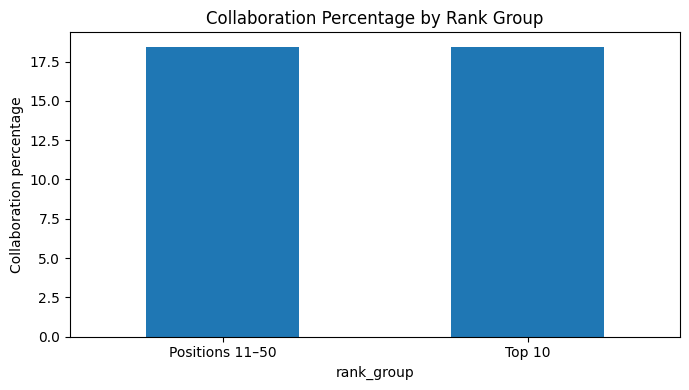

In [22]:
df["rank_group"] = np.where(
    df["position"] <= 10,
    "Top 10",
    "Positions 11–50"
)

collab_by_rank = (
    df.groupby("rank_group")["track_type"]
    .apply(lambda x: (x == "Collaboration").mean() * 100)
)

display(collab_by_rank)

collab_by_rank.plot(kind="bar", figsize=(7, 4))
plt.title("Collaboration Percentage by Rank Group")
plt.ylabel("Collaboration percentage")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [23]:
#individual artist appearances count in each track
all_artists = [
    artist
    for artist_list in df["artist_list"]
    for artist in artist_list
]

artist_counts = Counter(all_artists)
total_artist_appearances = sum(artist_counts.values())
unique_artist_count = len(artist_counts)
total_entries = len(df)

# 1. Top 5 Artists Share
top5_appearances = sum(
    count for artist, count in artist_counts.most_common(5)
)

top5_share = (
    top5_appearances / total_artist_appearances * 100
    if total_artist_appearances else 0
)

# 2. Diversity Score
diversity_score = (
    unique_artist_count / total_entries
    if total_entries else 0
)

# 3. Content Variety Index
content_categories = (
    df["album_type"].fillna("Unknown").astype(str)
    + " | "
    + df["is_explicit"].map({
        True: "Explicit",
        False: "Clean"
    })
)

category_shares = content_categories.value_counts(normalize=True)

if len(category_shares) > 1:
    entropy = -(category_shares * np.log(category_shares)).sum()
    content_variety_index = entropy / np.log(len(category_shares))
else:
    content_variety_index = 0.0

# Results table
market_metrics = pd.DataFrame({
    "Metric": [
        "Playlist Concentration Ratio (Top 5 Share)",
        "Diversity Score",
        "Content Variety Index"
    ],
    "Value": [
        f"{top5_share:.2f}%",
        f"{diversity_score:.4f}",
        f"{content_variety_index:.4f}"
    ]
})

display(market_metrics)# Har track mein individual artist appearances count karo
all_artists = [
    artist
    for artist_list in df["artist_list"]
    for artist in artist_list
]

artist_counts = Counter(all_artists)
total_artist_appearances = sum(artist_counts.values())
unique_artist_count = len(artist_counts)
total_entries = len(df)

# 1. Top 5 Artists Share
top5_appearances = sum(
    count for artist, count in artist_counts.most_common(5)
)

top5_share = (
    top5_appearances / total_artist_appearances * 100
    if total_artist_appearances else 0
)

# 2. Diversity Score
diversity_score = (
    unique_artist_count / total_entries
    if total_entries else 0
)

# 3. Content Variety Index
content_categories = (
    df["album_type"].fillna("Unknown").astype(str)
    + " | "
    + df["is_explicit"].map({
        True: "Explicit",
        False: "Clean"
    })
)

category_shares = content_categories.value_counts(normalize=True)

if len(category_shares) > 1:
    entropy = -(category_shares * np.log(category_shares)).sum()
    content_variety_index = entropy / np.log(len(category_shares))
else:
    content_variety_index = 0.0

# Results table
market_metrics = pd.DataFrame({
    "Metric": [
        "Playlist Concentration Ratio (Top 5 Share)",
        "Diversity Score",
        "Content Variety Index"
    ],
    "Value": [
        f"{top5_share:.2f}%",
        f"{diversity_score:.4f}",
        f"{content_variety_index:.4f}"
    ]
})

display(market_metrics)# Har track mein individual artist appearances count karo
all_artists = [
    artist
    for artist_list in df["artist_list"]
    for artist in artist_list
]

artist_counts = Counter(all_artists)
total_artist_appearances = sum(artist_counts.values())
unique_artist_count = len(artist_counts)
total_entries = len(df)

# 1. Top 5 Artists Share
top5_appearances = sum(
    count for artist, count in artist_counts.most_common(5)
)

top5_share = (
    top5_appearances / total_artist_appearances * 100
    if total_artist_appearances else 0
)

# 2. Diversity Score
diversity_score = (
    unique_artist_count / total_entries
    if total_entries else 0
)

# 3. Content Variety Index
content_categories = (
    df["album_type"].fillna("Unknown").astype(str)
    + " | "
    + df["is_explicit"].map({
        True: "Explicit",
        False: "Clean"
    })
)

category_shares = content_categories.value_counts(normalize=True)

if len(category_shares) > 1:
    entropy = -(category_shares * np.log(category_shares)).sum()
    content_variety_index = entropy / np.log(len(category_shares))
else:
    content_variety_index = 0.0

# Results table
market_metrics = pd.DataFrame({
    "Metric": [
        "Playlist Concentration Ratio (Top 5 Share)",
        "Diversity Score",
        "Content Variety Index"
    ],
    "Value": [
        f"{top5_share:.2f}%",
        f"{diversity_score:.4f}",
        f"{content_variety_index:.4f}"
    ]
})

display(market_metrics)# Har track mein individual artist appearances count karo
all_artists = [
    artist
    for artist_list in df["artist_list"]
    for artist in artist_list
]

artist_counts = Counter(all_artists)
total_artist_appearances = sum(artist_counts.values())
unique_artist_count = len(artist_counts)
total_entries = len(df)

# 1. Top 5 Artists Share
top5_appearances = sum(
    count for artist, count in artist_counts.most_common(5)
)

top5_share = (
    top5_appearances / total_artist_appearances * 100
    if total_artist_appearances else 0
)

# 2. Diversity Score
diversity_score = (
    unique_artist_count / total_entries
    if total_entries else 0
)

# 3. Content Variety Index
content_categories = (
    df["album_type"].fillna("Unknown").astype(str)
    + " | "
    + df["is_explicit"].map({
        True: "Explicit",
        False: "Clean"
    })
)

category_shares = content_categories.value_counts(normalize=True)

if len(category_shares) > 1:
    entropy = -(category_shares * np.log(category_shares)).sum()
    content_variety_index = entropy / np.log(len(category_shares))
else:
    content_variety_index = 0.0

# Results table
market_metrics = pd.DataFrame({
    "Metric": [
        "Playlist Concentration Ratio (Top 5 Share)",
        "Diversity Score",
        "Content Variety Index"
    ],
    "Value": [
        f"{top5_share:.2f}%",
        f"{diversity_score:.4f}",
        f"{content_variety_index:.4f}"
    ]
})

display(market_metrics)

,Metric,Value
0,Playlist Concentration Ratio (Top 5 Share),15.01%
1,Diversity Score,0.0131
2,Content Variety Index,0.8164


,Metric,Value
0,Playlist Concentration Ratio (Top 5 Share),15.01%
1,Diversity Score,0.0131
2,Content Variety Index,0.8164


,Metric,Value
0,Playlist Concentration Ratio (Top 5 Share),15.01%
1,Diversity Score,0.0131
2,Content Variety Index,0.8164


,Metric,Value
0,Playlist Concentration Ratio (Top 5 Share),15.01%
1,Diversity Score,0.0131
2,Content Variety Index,0.8164


In [24]:
#Key Performance Indicators

unique_artists = len({
    artist
    for artists in df["artist_list"]
    for artist in artists
})

artist_appearances = (
    df.explode("artist_list")["artist_list"]
      .value_counts()
)

top5_share = (
    artist_appearances.head(5).sum() /
    max(artist_appearances.sum(), 1) * 100
)

collab_ratio = df["is_collab"].mean() * 100
explicit_share = df["is_explicit"].mean() * 100
avg_duration = df["duration_min"].mean()

album_counts = df["album_type"].value_counts()
single_count = int(album_counts.get("Single", 0))
album_count = int(album_counts.get("Album", 0))
single_album_ratio = (
    single_count / album_count if album_count else np.nan
)

artist_concentration_index = (
    (artist_appearances / artist_appearances.sum()) ** 2
).sum()

diversity_score = unique_artists / max(len(df), 1) * 100

kpi_table = pd.DataFrame({
    "KPI": [
        "Unique Artists",
        "Top 5 Artist Appearance Share (%)",
        "Collaboration Ratio (%)",
        "Explicit Content Share (%)",
        "Single-to-Album Ratio",
        "Average Track Duration (minutes)",
        "Artist Concentration Index (HHI)",
        "Diversity Score (%)"
    ],
    "Value": [
        unique_artists,
        round(top5_share, 2),
        round(collab_ratio, 2),
        round(explicit_share, 2),
        round(single_album_ratio, 2) if pd.notna(single_album_ratio) else "N/A",
        round(avg_duration, 2),
        round(artist_concentration_index, 4),
        round(diversity_score, 2)
    ]
})

display(kpi_table)


,KPI,Value
0,Unique Artists,363.0000
1,Top 5 Artist Appearance Share (%),15.0100
2,Collaboration Ratio (%),18.4300
3,Explicit Content Share (%),32.0500
4,Single-to-Album Ratio,0.6600
5,Average Track Duration (minutes),3.2900
6,Artist Concentration Index (HHI),0.0114
7,Diversity Score (%),1.3100


In [25]:
df.drop(
    columns=["artist_list"],
    errors="ignore"
).to_csv("atlantic_uk_top50_cleaned.csv", index=False)

artist_data.to_csv(
    "artist_appearances.csv",
    index=False
)

kpi_table.to_csv(
    "project_kpis.csv",
    index=False
)

print("Project outputs saved successfully.")

files.download("atlantic_uk_top50_cleaned.csv")
files.download("project_kpis.csv")

Project outputs saved successfully.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [27]:
# Project insights and recommendations

if len(artist_counts):
    top_artist_tuple = artist_counts.most_common(1)[0]
    top_artist = top_artist_tuple[0]
    top_artist_appearances = int(top_artist_tuple[1])
else:
    top_artist = "N/A"
    top_artist_appearances = 0

top10_rate = (
    df.loc[df["position"] <= 10, "is_collab"].mean() * 100
    if (df["position"] <= 10).any() else 0
)

rest_rate = (
    df.loc[df["position"] > 10, "is_collab"].mean() * 100
    if (df["position"] > 10).any() else 0
)

display(Markdown("## Project Insights"))

display(Markdown(
    f"**1. Artist diversity:** The dataset contains **{unique_artists} unique artists**. "
    f"The five most frequent artists account for **{top5_share:.2f}%** of all artist appearances."
))

display(Markdown(
    f"**2. Collaboration trend:** Collaboration rate is **{top10_rate:.2f}%** in the Top 10 "
    f"and **{rest_rate:.2f}%** in positions 11–50."
))

display(Markdown(
    f"**3. Content and release strategy:** Explicit tracks account for **{explicit_share:.2f}%** "
    f"of entries. The most frequent artist is **{top_artist}** with "
    f"**{top_artist_appearances} appearances**."
))

display(Markdown(
    "**Recommendation:** Compare these results across different dates before making "
    "signing or marketing decisions. A single playlist snapshot cannot prove long-term trends."
))

## Project Insights

**1. Artist diversity:** The dataset contains **363 unique artists**. The five most frequent artists account for **15.01%** of all artist appearances.

**2. Collaboration trend:** Collaboration rate is **18.44%** in the Top 10 and **18.43%** in positions 11–50.

**3. Content and release strategy:** Explicit tracks account for **32.05%** of entries. The most frequent artist is **Taylor Swift** with **2092 appearances**.

**Recommendation:** Compare these results across different dates before making signing or marketing decisions. A single playlist snapshot cannot prove long-term trends.

In [28]:
#Save output files
from google.colab import files

df.to_csv("UK_Top_50_Cleaned.csv", index=False)
kpi_table.to_csv("UK_Top_50_KPI_Report.csv", index=False)
network_summary.to_csv("UK_Top_50_Collaboration_Network.csv", index=False) if "network_summary" in globals() else None

print("Files created successfully.")

files.download("UK_Top_50_Cleaned.csv")
files.download("UK_Top_50_KPI_Report.csv")


Files created successfully.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [29]:
with open("app.py", "w") as f:
    f.write('''
import streamlit as st
import pandas as pd
from collections import Counter
import plotly.express as px

st.set_page_config(page_title="UK Top 50 Analysis", layout="wide")
st.title("UK Top 50 - Market Structure & Diversity")

# --- Data Load ---
df = pd.read_csv("Atlantic_United_Kingdom.csv")
df.columns = df.columns.str.strip().str.lower()

# --- Cleaning (Tera Cell 3 wala) ---
df["is_explicit"] = df["is_explicit"].astype(str).str.lower() == "true"
df["artist_list"] = df["artist_name"].astype(str).apply(lambda x: [a.strip() for a in x.split(",")])
df["is_collab"] = df["artist_list"].apply(lambda x: len(x) > 1)

# --- KPI Code (Teri photo [24] wali - PEHLE) ---
all_artists = [artist for sublist in df["artist_list"] for artist in sublist]
artist_counts = Counter(all_artists)
top5_count = sum([count for artist, count in artist_counts.most_common(5)])
top5_share = top5_count / len(df) * 100 if len(df) > 0 else 0
diversity_score = len(artist_counts) / len(df) * 100 if len(df) > 0 else 0

# Display KPI
col1, col2, col3 = st.columns(3)
col1.metric("Top 5 Artists Share", f"{top5_share:.1f}%")
col2.metric("Artist Diversity Score", f"{diversity_score:.1f}%")
col3.metric("Total Tracks", len(df))

# --- Graph (Chota kiya hua - height=350) ---
st.subheader("Single vs Album Distribution")
album_summary = df["album_type"].value_counts().reset_index()
album_summary.columns = ["Album Type", "Track Count"]

fig = px.bar(
    album_summary,
    x="Album Type",
    y="Track Count",
    color="Album Type",
    text="Track Count",
    title="Single vs Album Distribution",
    height=350,
    width=500
)
st.plotly_chart(fig, use_container_width=False)

st.dataframe(df.head())
''')

print("app.py created! ✅")

app.py created! ✅


In [30]:
!pip install -q streamlit plotly pandas numpy

In [31]:

%%writefile app.py

import streamlit as st
import pandas as pd
import numpy as np
import plotly.express as px
from collections import Counter

st.set_page_config(
    page_title="UK Top 50 Music Analytics",
    page_icon="🎵",
    layout="wide"
)

st.title("🎵 UK Top 50 Music Analytics")
st.subheader("Market Structure & Artist Diversity Analysis")
st.markdown(
    "Explore artist concentration, chart rankings, "
    "collaborations, and music characteristics."
)

# -----------------------------
# 1. Load Dataset
# -----------------------------
@st.cache_data
def load_data():
    df = pd.read_csv("Atlantic_United_Kingdom.csv")
    df.columns = df.columns.str.strip().str.lower()

    required = [
        "date", "position", "song", "artist",
        "duration_ms", "album_type", "is_explicit"
    ]

    missing = [c for c in required if c not in df.columns]

    if missing:
        raise ValueError(f"Missing columns: {missing}")

    df["date"] = pd.to_datetime(
        df["date"], dayfirst=True, errors="coerce"
    )
    df["position"] = pd.to_numeric(
        df["position"], errors="coerce"
    )
    df["duration_ms"] = pd.to_numeric(
        df["duration_ms"], errors="coerce"
    )
    df["popularity"] = pd.to_numeric(
        df["popularity"], errors="coerce"
    ) if "popularity" in df.columns else np.nan

    df = df.dropna(
        subset=["date", "position", "song", "artist"]
    ).copy()

    for col in ["song", "artist", "album_type"]:
        df[col] = df[col].fillna("Unknown").astype(str).str.strip()

    df["is_explicit"] = (
        df["is_explicit"].astype(str).str.lower()
        .isin(["true", "1", "yes", "y", "explicit"])
    )

    # The source data separates artist names with &
    df["artist_list"] = df["artist"].apply(
        lambda x: list(dict.fromkeys(
            a.strip() for a in x.split("&") if a.strip()
        ))
    )

    df["duration_min"] = df["duration_ms"] / 60000
    df["is_collab"] = df["artist_list"].apply(
        lambda x: len(x) > 1
    )
    df["rank_group"] = np.where(
        df["position"] <= 10,
        "Top 10",
        "Positions 11–50"
    )

    return df


try:
    df = load_data()
except Exception as e:
    st.error(f"Unable to load dataset: {e}")
    st.stop()

# -----------------------------
# 2. Sidebar Filters
# -----------------------------
st.sidebar.header("Dashboard Filters")

min_date = df["date"].min().date()
max_date = df["date"].max().date()

date_range = st.sidebar.date_input(
    "Select date range",
    value=(min_date, max_date),
    min_value=min_date,
    max_value=max_date
)

if isinstance(date_range, (tuple, list)) and len(date_range) == 2:
    start_date, end_date = date_range
    filtered = df[
        df["date"].dt.date.between(start_date, end_date)
    ].copy()
else:
    filtered = df.copy()

rank_options = ["All", "Top 10", "Positions 11–50"]

selected_rank = st.sidebar.selectbox(
    "Chart position group", rank_options
)

if selected_rank != "All":
    filtered = filtered[
        filtered["rank_group"] == selected_rank
    ].copy()

album_options = ["All"] + sorted(
    filtered["album_type"].dropna().unique().tolist()
)

selected_album = st.sidebar.selectbox(
    "Album type", album_options
)

if selected_album != "All":
    filtered = filtered[
        filtered["album_type"] == selected_album
    ].copy()

if filtered.empty:
    st.warning("No records match the selected filters.")
    st.stop()

# -----------------------------
# 3. Calculate KPIs
# -----------------------------
artist_counts = Counter(
    artist
    for artists in filtered["artist_list"]
    for artist in artists
)

total_artist_appearances = sum(artist_counts.values())
unique_artists = len(artist_counts)

top5_share = (
    sum(count for _, count in artist_counts.most_common(5))
    / total_artist_appearances * 100
    if total_artist_appearances else 0
)

diversity_score = (
    unique_artists / len(filtered) * 100
    if len(filtered) else 0
)

collab_rate = filtered["is_collab"].mean() * 100
explicit_rate = filtered["is_explicit"].mean() * 100
avg_duration = filtered["duration_min"].mean()

artist_shares = (
    pd.Series(artist_counts, dtype=float)
    / max(total_artist_appearances, 1)
)

hhi = (artist_shares ** 2).sum()

st.subheader("Key Performance Indicators")

k1, k2, k3, k4 = st.columns(4)
k1.metric("Track Entries", f"{len(filtered):,}")
k2.metric("Unique Artists", f"{unique_artists:,}")
k3.metric("Top 5 Artist Share", f"{top5_share:.2f}%")
k4.metric("Collaboration Rate", f"{collab_rate:.2f}%")

k5, k6, k7, k8 = st.columns(4)
k5.metric("Explicit Content", f"{explicit_rate:.2f}%")
k6.metric("Average Duration", f"{avg_duration:.2f} min")
k7.metric("Artist Diversity Score", f"{diversity_score:.2f}%")
k8.metric("Artist HHI", f"{hhi:.4f}")

st.caption(
    "Diversity score = unique artists / filtered track entries. "
    "HHI = sum of squared artist appearance shares."
)

# -----------------------------
# 4. Artist Leaderboard
# -----------------------------
st.divider()
st.subheader("🏆 Top 15 Artists")

leaderboard = pd.DataFrame(
    artist_counts.most_common(15),
    columns=["Artist", "Appearances"]
)

fig = px.bar(
    leaderboard.sort_values("Appearances"),
    x="Appearances",
    y="Artist",
    orientation="h",
    text="Appearances",
    title="Artists by Individual Track Appearances"
)

fig.update_layout(yaxis={"categoryorder": "total ascending"})
st.plotly_chart(fig, use_container_width=True)

# -----------------------------
# 5. Rank Analysis
# -----------------------------
st.subheader("📊 Chart Position Analysis")

rank_summary = (
    filtered.groupby("rank_group", observed=False)
    .agg(
        Track_Count=("song", "size"),
        Average_Duration=("duration_min", "mean"),
        Collaboration_Rate=("is_collab", "mean"),
        Explicit_Rate=("is_explicit", "mean")
    )
    .reset_index()
)

rank_summary["Collaboration_Rate"] *= 100
rank_summary["Explicit_Rate"] *= 100

left, right = st.columns(2)

with left:
    fig = px.bar(
        rank_summary,
        x="rank_group",
        y="Collaboration_Rate",
        text_auto=".2f",
        title="Collaboration Rate by Rank Group"
    )
    st.plotly_chart(fig, use_container_width=True)

with right:
    fig = px.bar(
        rank_summary,
        x="rank_group",
        y="Explicit_Rate",
        text_auto=".2f",
        title="Explicit Content Rate by Rank Group"
    )
    st.plotly_chart(fig, use_container_width=True)

# -----------------------------
# 6. Album Type Analysis
# -----------------------------
st.subheader("💿 Album Type Distribution")

album_summary = (
    filtered["album_type"].value_counts()
    .rename_axis("Album Type")
    .reset_index(name="Track Count")
)

left, right = st.columns(2)

with left:
    fig = px.pie(
        album_summary,
        names="Album Type",
        values="Track Count",
        hole=0.45,
        title="Distribution of Album Types"
    )
    st.plotly_chart(fig, use_container_width=True)

with right:
    fig = px.bar(
        album_summary,
        x="Album Type",
        y="Track Count",
        text="Track Count",
        title="Entries by Album Type"
    )
    st.plotly_chart(fig, use_container_width=True)

# -----------------------------
# 7. Track Duration Analysis
# -----------------------------
st.subheader("⏱️ Track Duration Analysis")

duration_data = filtered.dropna(subset=["duration_min"])

fig = px.histogram(
    duration_data,
    x="duration_min",
    nbins=30,
    title="Distribution of Track Durations",
    labels={"duration_min": "Duration (minutes)"}
)
st.plotly_chart(fig, use_container_width=True)

if filtered["popularity"].notna().any():
    fig = px.scatter(
        filtered.dropna(
            subset=["duration_min", "popularity"]
        ),
        x="duration_min",
        y="popularity",
        hover_data=["song", "artist", "position"],
        title="Track Duration vs Popularity"
    )
    st.plotly_chart(fig, use_container_width=True)

    corr = filtered[
        ["duration_min", "popularity"]
    ].corr().iloc[0, 1]

    st.write(f"Duration-popularity correlation: {corr:.3f}")

# -----------------------------
# 8. Artist Appearance Table
# -----------------------------
st.subheader("🎤 Artist Appearance Details")

artist_table = leaderboard.copy()
st.dataframe(artist_table, use_container_width=True)

# -----------------------------
# 9. Filtered Dataset
# -----------------------------
st.subheader("📁 Filtered Dataset")

display_df = filtered.drop(
    columns=["artist_list"], errors="ignore"
)

st.dataframe(display_df, use_container_width=True)

csv_data = display_df.to_csv(index=False).encode("utf-8")

st.download_button(
    "Download Filtered CSV",
    data=csv_data,
    file_name="UK_Top_50_Filtered.csv",
    mime="text/csv"
)

st.success("Dashboard loaded successfully.")


Overwriting app.py


In [38]:
!pip install -q pyngrok

# Delete old config file to prevent "Authtoken already set" error
!rm -rf /root/.config/ngrok/ngrok.yml

from google.colab import userdata
from pyngrok import ngrok

NGROK_TOKEN = userdata.get('NGROK_TOKEN')
ngrok.set_auth_token(NGROK_TOKEN)

In [40]:
# 1. Delete old config file causing the error
!rm -rf /root/.config/ngrok/ngrok.yml

# Force check and install pyngrok inside the same cell run
try:
    from pyngrok import ngrok
except ImportError:
    !pip install -q pyngrok
    from pyngrok import ngrok

from google.colab import userdata
import os, time

# 2. Get token from Colab Secrets
try:
    NGROK_TOKEN = userdata.get('NGROK_T')
except:
    NGROK_TOKEN = userdata.get('NGROK_TOKEN')

print(f"Token found: {str(NGROK_TOKEN)[:5]}...")

# 3. Set the auth token
ngrok.set_auth_token(NGROK_TOKEN)

# 4. Start Streamlit and generate public link
os.system("pkill -f streamlit")
time.sleep(2)
os.system("streamlit run app.py --server.port 8501 > /dev/null 2>&1 &")
time.sleep(6)

public_url = ngrok.connect(8501)
print(f"LIVE LINK: {public_url}")

Token found: 3KJV9...
LIVE LINK: NgrokTunnel: "https://upward-silencer-botany.ngrok-free.dev" -> "http://localhost:8501"
